# Why the anomaly detector no longer uses absolute fluxes

Ablation study comparing the original 6D feature space (which included raw $\mathrm{H}\alpha$ and $[\mathrm{O\ III}]$ line fluxes) against the 4D ratio-only feature space ($\log([\mathrm{N\ II}]/\mathrm{H}\alpha)$, $\log([\mathrm{O\ III}]/\mathrm{H}\beta)$, $\log(\mathrm{H}\alpha/\mathrm{H}\beta)$, and $\log \mathrm{EW}(\mathrm{H}\alpha)$).

This experiment measures how absolute line brightness corrupted the unsupervised outlier detector with Malmquist distance bias and extreme-flux artifacts, and demonstrates the statistical behavior of scale-invariant line ratios.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
from scipy.stats import rankdata, spearmanr
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.decomposition import PCA
from sklearn.preprocessing import RobustScaler
import matplotlib.pyplot as plt

# Add src to path
sys.path.insert(0, os.path.abspath("../src"))

# Load baseline sample (commit 902d696) and current sample (DR17)
baseline_path = (
    "baseline_902d696/data/sdss_bpt_sample.csv" 
    if os.path.exists("baseline_902d696/data/sdss_bpt_sample.csv") 
    else "baseline_902d696/sdss_bpt_sample.csv"
)
df_baseline = pd.read_csv(baseline_path)
df_current = pd.read_csv("../data/sdss_bpt_sample.csv")

print(f"Loaded baseline sample: {len(df_baseline):,} galaxies ({baseline_path})")
print(f"Loaded current sample:  {len(df_current):,} galaxies (data/sdss_bpt_sample.csv)")

Loaded baseline sample: 9,999 galaxies (notebooks/baseline_902d696/data/sdss_bpt_sample.csv)
Loaded current sample:  10,000 galaxies (data/sdss_bpt_sample.csv)


In [2]:
# Old feature extractor (reconstructed from commit 902d696:src/anomaly_detector.py)
def extract_old_features(df):
    ha = np.maximum(df["h_alpha_flux"].values, 1e-4)
    hb = np.maximum(df["h_beta_flux"].values, 1e-4)
    oiii = np.maximum(df["oiii_5007_flux"].values, 1e-4)
    nii = np.maximum(df["nii_6584_flux"].values, 1e-4)
    
    log_nii_ha = df["log_nii_ha"].values
    log_oiii_hb = df["log_oiii_hb"].values
    log_balmer = np.log10(ha / hb)
    log_oiii_nii = np.log10(oiii / nii)
    log_ha = np.log10(ha)
    log_oiii = np.log10(oiii)
    
    features = np.column_stack([
        log_nii_ha,
        log_oiii_hb,
        log_balmer,
        log_oiii_nii,
        log_ha,
        log_oiii
    ])
    scaler = RobustScaler()
    return scaler.fit_transform(features)

# New ratio-only feature extractor (Task T2.1)
from anomaly_detector import extract_anomaly_features

def extract_new_features(df):
    X_scaled, _, _ = extract_anomaly_features(df)
    return X_scaled

def to_percentile_score(raw_scores: np.ndarray) -> np.ndarray:
    ranks = rankdata(raw_scores, method="average")
    return np.round((ranks / len(raw_scores)) * 100.0, 2)

def run_ensemble(X, random_state=42, dynamic_pca=False, contamination="auto"):
    # 1. Isolation Forest
    iso = IsolationForest(
        n_estimators=250,
        contamination=contamination,
        max_samples="auto",
        random_state=random_state,
        n_jobs=-1
    )
    iso.fit(X)
    score_iforest = to_percentile_score(-iso.decision_function(X))
    
    # 2. Local Outlier Factor
    lof = LocalOutlierFactor(
        n_neighbors=35,
        contamination=contamination,
        n_jobs=-1
    )
    lof.fit_predict(X)
    score_lof = to_percentile_score(-lof.negative_outlier_factor_)
    
    # 3. PCA Reconstruction Residual
    if dynamic_pca:
        pca_full = PCA().fit(X)
        cum = np.cumsum(pca_full.explained_variance_ratio_)
        n_comp = int(min(max(1, np.searchsorted(cum, 0.90) + 1), X.shape[1] - 1))
        pca = PCA(n_components=n_comp, random_state=random_state).fit(X)
    else:
        pca = PCA(n_components=2, random_state=random_state).fit(X)
        
    X_recon = pca.inverse_transform(pca.transform(X))
    raw_pca_err = np.linalg.norm(X - X_recon, axis=1)
    score_pca = to_percentile_score(raw_pca_err)
    
    consensus = np.round((score_iforest + score_lof + score_pca) / 3.0, 2)
    return {
        "iforest": score_iforest,
        "lof": score_lof,
        "pca": score_pca,
        "consensus": consensus
    }

# Execute both feature sets on current sample with seed 42
X_old = extract_old_features(df_current)
X_new = extract_new_features(df_current)

res_old = run_ensemble(X_old, random_state=42, dynamic_pca=False, contamination=0.03)
res_new = run_ensemble(X_new, random_state=42, dynamic_pca=True, contamination="auto")

top20_old_idx = np.argsort(-res_old["consensus"])[:20]
top20_new_idx = np.argsort(-res_new["consensus"])[:20]

df_top20_old = df_current.iloc[top20_old_idx].copy()
df_top20_new = df_current.iloc[top20_new_idx].copy()

print("Top 20 candidates extracted for both paradigms on current DR17 sample.")

Top 20 candidates extracted for both paradigms on current DR17 sample.


In [3]:
med_z_old = df_top20_old["z"].median()
med_z_new = df_top20_new["z"].median()

med_ha_old = df_top20_old["h_alpha_flux"].median()
med_ha_new = df_top20_new["h_alpha_flux"].median()

frac_z_old = (df_top20_old["z"] < 0.06).mean()
frac_z_new = (df_top20_new["z"] < 0.06).mean()

set_old = set(df_top20_old["specObjID"])
set_new = set(df_top20_new["specObjID"])
jaccard = len(set_old & set_new) / len(set_old | set_new)

df_comparison = pd.DataFrame({
    "Feature Configuration": [
        "Old Features (6D: Line Ratios + Fluxes)", 
        "New Features (4D: Scale-Invariant Line Ratios)"
    ],
    "Median Redshift z": [f"{med_z_old:.4f}", f"{med_z_new:.4f}"],
    "Median H-alpha Flux": [f"{med_ha_old:,.1f}", f"{med_ha_new:,.1f}"],
    "Fraction z < 0.06": [f"{frac_z_old:.1%}", f"{frac_z_new:.1%}"],
    "Top-20 Jaccard Overlap": [f"{jaccard:.3f}", f"{jaccard:.3f}"]
})
df_comparison

Feature Configuration,Median Redshift z,Median H-alpha Flux,Fraction z < 0.06,Top-20 Jaccard Overlap
Old Features (6D: Line Ratios + Fluxes),0.1393,"7,665,108,000.0",20.0%,0.176
New Features (4D: Scale-Invariant Line Ratios),0.0520,115.8,60.0%,0.176


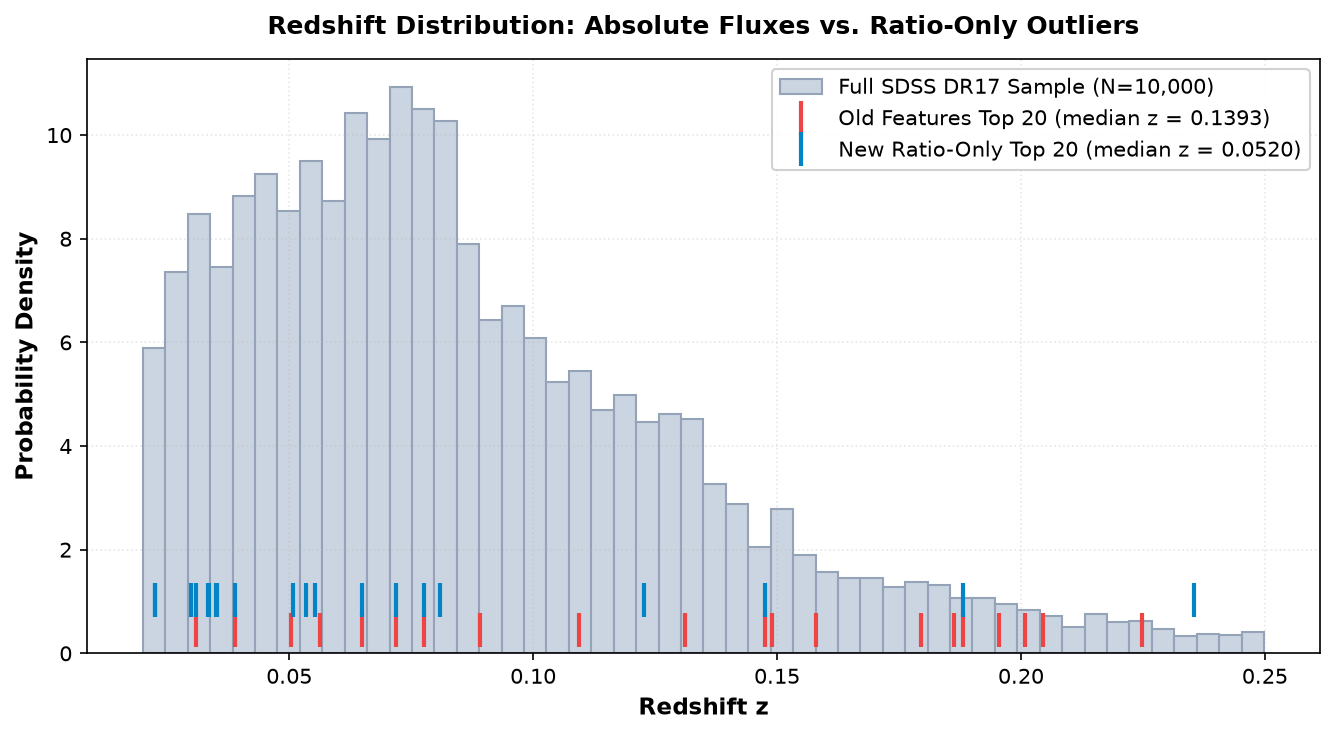

In [4]:
fig, ax = plt.subplots(figsize=(9, 5), dpi=150)
ax.hist(
    df_current["z"], 
    bins=50, 
    density=True, 
    color="#cbd5e1", 
    edgecolor="#94a3b8", 
    label=f"Full SDSS DR17 Sample (N={len(df_current):,})"
)

# Overplot top-20 rug marks
z_old = df_top20_old["z"].values
z_new = df_top20_new["z"].values
ymax = ax.get_ylim()[1]

ax.plot(
    z_old, 
    np.full_like(z_old, ymax * 0.04), 
    "|", 
    color="#ef4444", 
    markersize=16, 
    markeredgewidth=2, 
    label=f"Old Features Top 20 (median z = {med_z_old:.4f})"
)
ax.plot(
    z_new, 
    np.full_like(z_new, ymax * 0.09), 
    "|", 
    color="#0284c7", 
    markersize=16, 
    markeredgewidth=2, 
    label=f"New Ratio-Only Top 20 (median z = {med_z_new:.4f})"
)

ax.set_xlabel("Redshift z", fontsize=11, fontweight="bold")
ax.set_ylabel("Probability Density", fontsize=11, fontweight="bold")
ax.set_title("Redshift Distribution: Absolute Fluxes vs. Ratio-Only Outliers", fontsize=12, fontweight="bold", pad=12)
ax.legend(frameon=True, facecolor="white", framealpha=0.9)
ax.grid(alpha=0.3, linestyle=":")
plt.tight_layout()
plt.show()

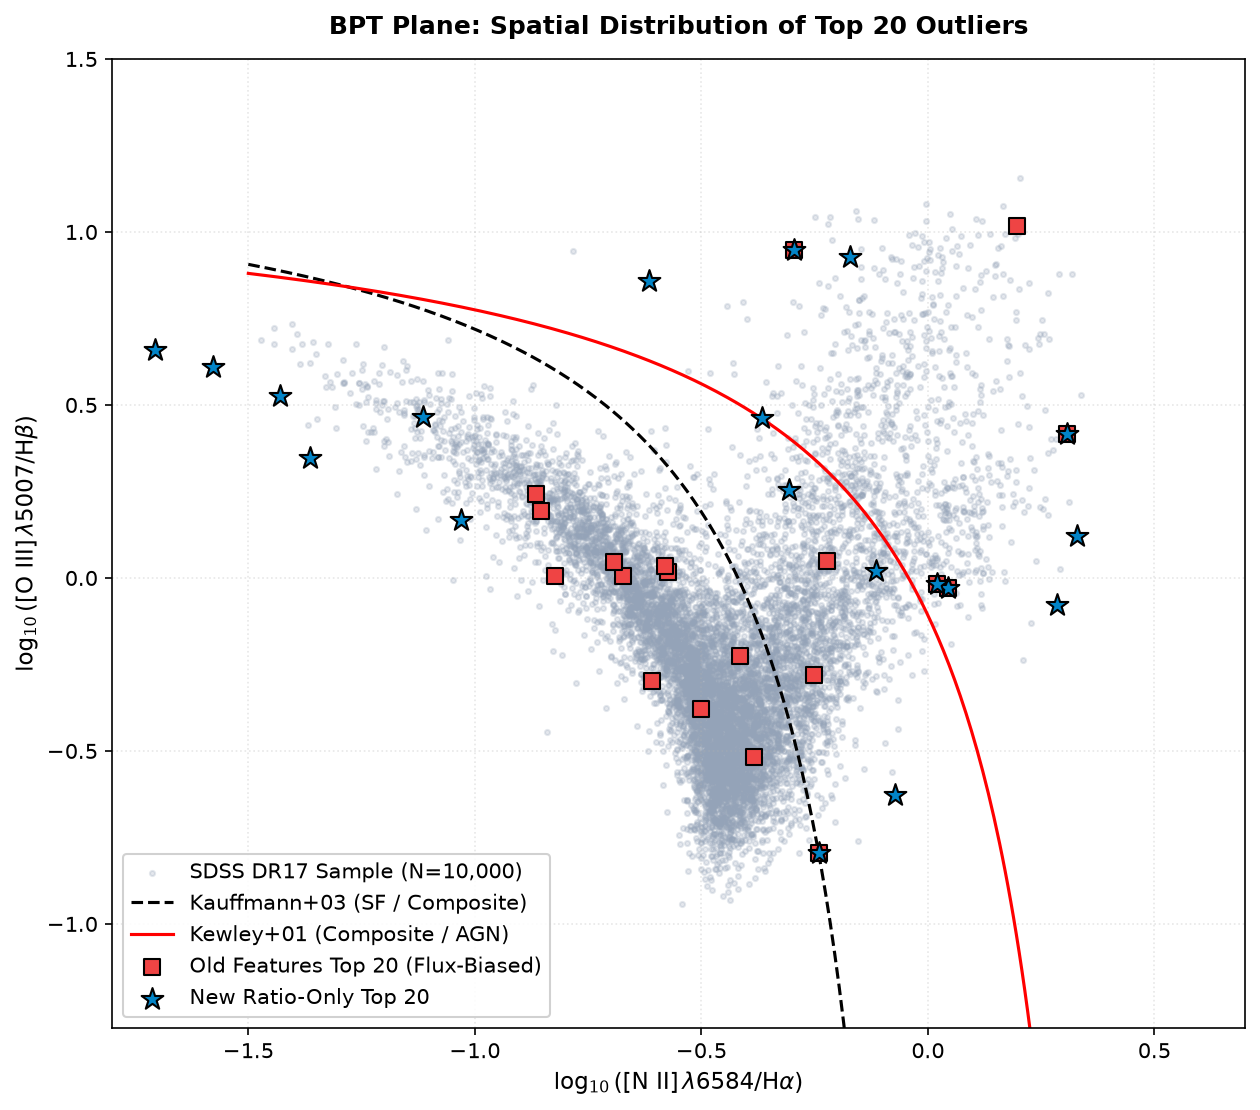

In [5]:
from bpt_math import kauffmann_boundary, kewley_boundary

fig, ax = plt.subplots(figsize=(8.5, 7.5), dpi=150)

# Full sample scatter
ax.scatter(
    df_current["log_nii_ha"], 
    df_current["log_oiii_hb"], 
    c="#94a3b8", 
    s=6, 
    alpha=0.25, 
    rasterized=True, 
    label=f"SDSS DR17 Sample (N={len(df_current):,})"
)

# Demarcation curves
x_k03 = np.linspace(-1.5, 0.0, 300)
ax.plot(x_k03, kauffmann_boundary(x_k03), "k--", lw=1.5, label="Kauffmann+03 (SF / Composite)")
x_k01 = np.linspace(-1.5, 0.35, 300)
ax.plot(x_k01, kewley_boundary(x_k01), "r-", lw=1.5, label="Kewley+01 (Composite / AGN)")

# Plot candidate sets
ax.scatter(
    df_top20_old["log_nii_ha"], 
    df_top20_old["log_oiii_hb"], 
    color="#ef4444", 
    marker="s", 
    s=65, 
    edgecolors="black", 
    lw=1.0, 
    zorder=4,
    label="Old Features Top 20 (Flux-Biased)"
)
ax.scatter(
    df_top20_new["log_nii_ha"], 
    df_top20_new["log_oiii_hb"], 
    color="#0284c7", 
    marker="*", 
    s=120, 
    edgecolors="black", 
    lw=1.0, 
    zorder=5,
    label="New Ratio-Only Top 20"
)

ax.set_xlim(-1.8, 0.7)
ax.set_ylim(-1.3, 1.5)
ax.set_xlabel(r"$\log_{10}([\mathrm{N\ II}]\,\lambda6584 / \mathrm{H}\alpha)$", fontsize=11, fontweight="bold")
ax.set_ylabel(r"$\log_{10}([\mathrm{O\ III}]\,\lambda5007 / \mathrm{H}\beta)$", fontsize=11, fontweight="bold")
ax.set_title("BPT Plane: Spatial Distribution of Top 20 Outliers", fontsize=12, fontweight="bold", pad=12)
ax.legend(frameon=True, facecolor="white", framealpha=0.9, loc="lower left")
ax.grid(alpha=0.3, linestyle=":")
plt.tight_layout()
plt.show()

In [6]:
log_ha_curr = np.log10(np.maximum(df_current["h_alpha_flux"].values, 1e-4))

corr_rows = []
for model_name, key in [
    ("Isolation Forest", "iforest"),
    ("Local Outlier Factor (LOF)", "lof"),
    ("PCA Reconstruction Residual", "pca"),
    ("Consensus Anomaly Score", "consensus")
]:
    r_old = spearmanr(log_ha_curr, res_old[key]).correlation
    r_new = spearmanr(log_ha_curr, res_new[key]).correlation
    corr_rows.append({
        "Detector Paradigm": model_name,
        "Spearman r (Old 6D Flux Features)": f"{r_old:+.4f}",
        "Spearman r (New 4D Ratio-Only)": f"{r_new:+.4f}"
    })

df_correlations = pd.DataFrame(corr_rows)
df_correlations

Detector Paradigm,Spearman r (Old 6D Flux Features),Spearman r (New 4D Ratio-Only)
Isolation Forest,+0.0370,-0.0067
Local Outlier Factor (LOF),+0.0347,+0.0348
PCA Reconstruction Residual,-0.0670,-0.0131
Consensus Anomaly Score,+0.0042,+0.0078


## What I expected
<!-- Aditya: 2–4 sentences, first person, written after looking at the cells above. Do not let an agent fill this. -->

## What the numbers show
<!-- Aditya: 2–4 sentences, first person, written after looking at the cells above. Do not let an agent fill this. -->

## Decision
<!-- Aditya: 2–4 sentences, first person, written after looking at the cells above. Do not let an agent fill this. -->